# Car Price Prediction — Oasis Infobyte Data Science Internship

**Official task:** Task 3 — Car Price Prediction  
**Project folder:** `DataScience-Task3-CarPricePrediction`  
**Task type:** Supervised machine learning — regression

## Project overview

The goal of this project is to estimate a used car's selling price from information such as its brand, age, kilometres driven, fuel type, seller type, transmission, ownership history, engine size, mileage, power, and seating capacity.

This notebook follows a complete, reproducible data-science workflow:

1. Load the supplied CSV and inspect its structure.
2. Clean duplicate records and invalid target values.
3. Explore the data using summary statistics and visualizations.
4. Prepare numerical and categorical features, including extracting a car brand and calculating car age.
5. Build a preprocessing-and-modeling pipeline to avoid data leakage.
6. Compare a simple baseline with multiple regression models.
7. Evaluate the selected model using MAE, RMSE, and R².
8. Examine feature importance and inspect predictions.
9. Save presentation-ready charts into the `screenshots` folder.

**Important:** This is a learning/internship project, not a professional vehicle valuation service. The data reflects the source dataset's market, listings, and time period; model scores should not be interpreted as guaranteed prices.

## 1. Before running the notebook

1. Download this notebook.
2. Place it in your project folder so the CSV and notebook have the following layout:

```text
DataScience-Task3-CarPricePrediction/
├── Car_Price_Prediction.ipynb
├── data/
│   └── car_details_v3.csv
└── screenshots/
```

3. Open the notebook from that project folder using Python/Jupyter environment.
4. Choose **Kernel → Restart Kernel and Run All Cells**.

## 2. Problem statement and machine-learning approach

### Problem statement

Used-car prices vary with vehicle characteristics. We will train a regression model that learns patterns in historical listings and predicts a numeric `selling_price`.

### Why regression?

The target (`selling_price`) is a continuous numeric value. This is a **regression** problem rather than a classification problem.

### Evaluation metrics

- **MAE (Mean Absolute Error):** the average absolute difference between actual and predicted prices. Lower is better.
- **RMSE (Root Mean Squared Error):** gives larger errors more influence than MAE. Lower is better.
- **R² (coefficient of determination):** indicates how much target variation is explained by the model relative to a mean-prediction baseline. Higher is generally better; it can be negative.

All price errors are expressed in the same currency units as `selling_price` in the dataset. The notebook does not assume or convert the currency.

## 3. Import libraries and create output folders

This cell imports the required packages, sets reproducibility options, and creates the screenshots folder if it does not already exist.

In [1]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
REFERENCE_YEAR = 2026  # Fixed reference year so the engineered age feature is reproducible.
PROJECT_DIR = Path.cwd()
DATA_PATH = PROJECT_DIR / "data" / "car_details_v3.csv"
SCREENSHOTS_DIR = PROJECT_DIR / "screenshots"
SCREENSHOTS_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

print("Working directory:", PROJECT_DIR)
print("Dataset path:", DATA_PATH)
print("Screenshots folder:", SCREENSHOTS_DIR)

Working directory: C:\Users\user\OIBSIP\OIBSIP\DataScience-Task3-CarPricePrediction
Dataset path: C:\Users\user\OIBSIP\OIBSIP\DataScience-Task3-CarPricePrediction\data\car_details_v3.csv
Screenshots folder: C:\Users\user\OIBSIP\OIBSIP\DataScience-Task3-CarPricePrediction\screenshots


## 4. Load the dataset

The dataset is loaded from the `data` folder. If the file is missing, stop here and check the folder structure described above. No manual path editing should be needed when the notebook is placed correctly.

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find the dataset at:\n{DATA_PATH}\n\n"
        "Make sure this notebook is saved in the project folder and the CSV is at "
        "'data/car_details_v3.csv'."
    )

df_original = pd.read_csv(DATA_PATH)
df = df_original.copy()

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
display(df.head())

Rows: 8,128
Columns: 13


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


## 5. Understand the data

First inspect the column names, data types, missing values, and duplicate rows. This is important because real-world datasets often contain incomplete records and numbers stored as text.

In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nMissing values by column:")
missing_summary = (
    df.isna().sum()
      .rename("missing_count")
      .to_frame()
)
missing_summary["missing_percent"] = (missing_summary["missing_count"] / len(df) * 100).round(2)
display(missing_summary.sort_values("missing_count", ascending=False))

print(f"\nExact duplicate rows: {df.duplicated().sum():,}")

Column names:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage', 'engine', 'max_power', 'torque', 'seats']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   str    
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   str    
 5   seller_type    8128 non-null   str    
 6   transmission   8128 non-null   str    
 7   owner          8128 non-null   str    
 8   mileage        7907 non-null   str    
 9   engine         7907 non-null   str    
 10  max_power      7913 non-null   str    
 11  torque         7906 non-null   str    
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), str(9)
memory usage

,missing_count,missing_percent
torque,222,2.73
seats,221,2.72
engine,221,2.72
mileage,221,2.72
max_power,215,2.65
fuel,0,0.00
km_driven,0,0.00
selling_price,0,0.00
year,0,0.00
name,0,0.00



Exact duplicate rows: 1,202


## 6. Clean the data and prepare features

The source contains vehicle specifications with units in text (for example, `23.4 kmpl`, `1248 CC`, and `74 bhp`). The helper function below extracts the first numeric value. This is suitable for the numeric specification columns used here; the complex `torque` field is intentionally not parsed because its formats vary.

We also remove exact duplicate rows, convert numeric columns safely, remove records with missing or non-positive target prices, derive `brand` from the first word of the car name, and calculate car age using the fixed reference year 2026. We keep the original dataset unchanged in `df_original` for reference.

In [4]:
# Standardize column labels in case the source file contains accidental spaces.
df.columns = [str(c).strip() for c in df.columns]

# Remove exact duplicate records.
rows_before = len(df)
df = df.drop_duplicates().copy()
print(f"Removed {rows_before - len(df):,} exact duplicate rows.")

# Convert values such as '23.4 kmpl', '1248 CC', and '74 bhp' into numeric values.
def extract_first_number(series):
    text = series.astype("string").str.replace(",", "", regex=False)
    extracted = text.str.extract(r"([-+]?\d*\.?\d+)")[0]
    return pd.to_numeric(extracted, errors="coerce")

for col in ["year", "selling_price", "km_driven", "mileage", "engine", "max_power", "seats"]:
    if col in df.columns:
        df[col] = extract_first_number(df[col])

# Clean text fields and make missing values consistent.
for col in ["name", "fuel", "seller_type", "transmission", "owner"]:
    if col in df.columns:
        df[col] = df[col].astype("string").str.strip()
        df[col] = df[col].replace({"": pd.NA, "nan": pd.NA, "None": pd.NA})

# Remove rows where the target is unknown or invalid.
before_target_filter = len(df)
df = df[df["selling_price"].notna() & (df["selling_price"] > 0)].copy()
print(f"Removed {before_target_filter - len(df):,} rows with missing/non-positive selling price.")

# Keep plausible years up to the reference year.
if "year" in df.columns:
    df = df[df["year"].notna() & (df["year"] >= 1950) & (df["year"] <= REFERENCE_YEAR)].copy()

# Feature engineering: derive brand and vehicle age.
df["brand"] = (
    df["name"].fillna("Unknown")
      .astype(str)
      .str.strip()
      .str.split()
      .str[0]
      .replace("", "Unknown")
)
df["car_age"] = REFERENCE_YEAR - df["year"]

# The full car name can have hundreds of distinct values. We use the brand as a
# more general categorical feature and exclude the raw name to reduce sparsity.
# The torque column is excluded because its formatting is inconsistent.
print("Cleaned dataset shape:", df.shape)
display(df.head())

Removed 1,202 exact duplicate rows.
Removed 0 rows with missing/non-positive selling price.
Cleaned dataset shape: (6926, 15)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,brand,car_age
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4,1248,74.0,190Nm@ 2000rpm,5.0,Maruti,12
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498,103.52,250Nm@ 1500-2500rpm,5.0,Skoda,12
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7,1497,78.0,"12.7@ 2,700(kgm@ rpm)",5.0,Honda,20
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0,1396,90.0,22.4 kgm at 1750-2750rpm,5.0,Hyundai,16
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1,1298,88.2,"11.5@ 4,500(kgm@ rpm)",5.0,Maruti,19


### Check the cleaned dataset

Review the updated missing-value counts and basic statistics. Missing predictor values are not automatically discarded; they will be imputed inside the modeling pipeline using training data only.

In [5]:
display(
    pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing_count": df.isna().sum(),
        "missing_percent": (df.isna().mean() * 100).round(2),
        "unique_values": df.nunique(dropna=True)
    }).sort_values("missing_count", ascending=False)
)

display(df[["selling_price", "year", "car_age", "km_driven", "mileage", "engine", "max_power", "seats"]].describe().T)

,dtype,missing_count,missing_percent,unique_values
torque,str,209,3.02,441
mileage,Float64,208,3.00,381
seats,Float64,208,3.00,9
engine,Int64,208,3.00,121
max_power,Float64,206,2.97,319
year,Int64,0,0.00,29
name,string,0,0.00,2058
transmission,string,0,0.00,2
seller_type,string,0,0.00,3
fuel,string,0,0.00,4


,count,mean,std,min,25%,50%,75%,max
selling_price,6926.0,517270.678458,519766.985985,29999.0,250000.0,400000.0,633500.0,10000000.0
year,6926.0,2013.4203,4.078286,1983.0,2011.0,2014.0,2017.0,2020.0
car_age,6926.0,12.5797,4.078286,6.0,9.0,12.0,15.0,43.0
km_driven,6926.0,73995.676437,58358.095175,1.0,40000.0,70000.0,100000.0,2360457.0
mileage,6718.0,19.46531,4.04915,0.0,16.8,19.44,22.5,42.0
engine,6718.0,1430.891337,493.493277,624.0,1197.0,1248.0,1498.0,3604.0
max_power,6720.0,87.726919,31.771619,0.0,67.1,81.83,100.0,400.0
seats,6718.0,5.434653,0.98423,2.0,5.0,5.0,5.0,14.0


## 7. Exploratory data analysis (EDA)

These visualizations help us understand target-price distribution, common car ages, fuel categories, and the relationship between kilometres driven and selling price. Charts are displayed in the notebook and saved as PNG files inside `screenshots/` for your GitHub submission.

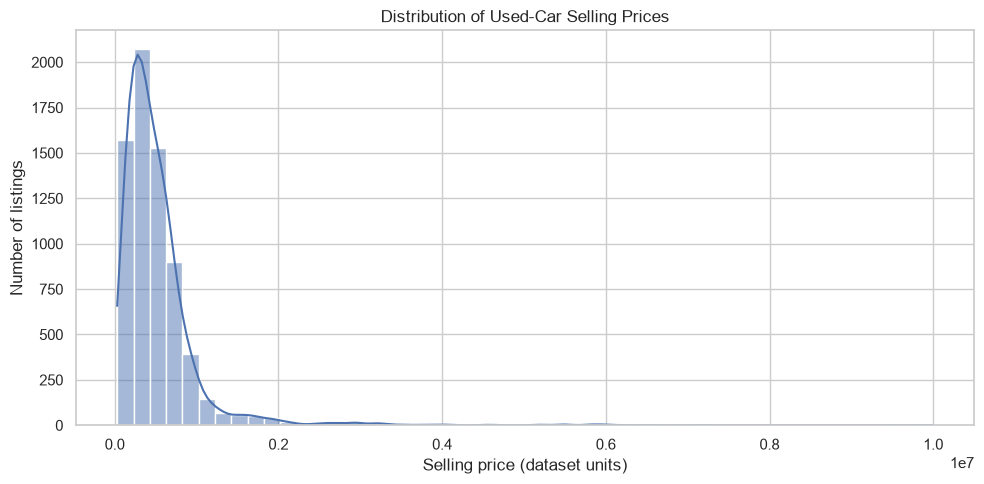

In [6]:
# 7.1 Distribution of selling price
plt.figure(figsize=(10, 5))
sns.histplot(df["selling_price"], bins=50, kde=True)
plt.title("Distribution of Used-Car Selling Prices")
plt.xlabel("Selling price (dataset units)")
plt.ylabel("Number of listings")
plt.tight_layout()
plt.savefig(SCREENSHOTS_DIR / "selling_price_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

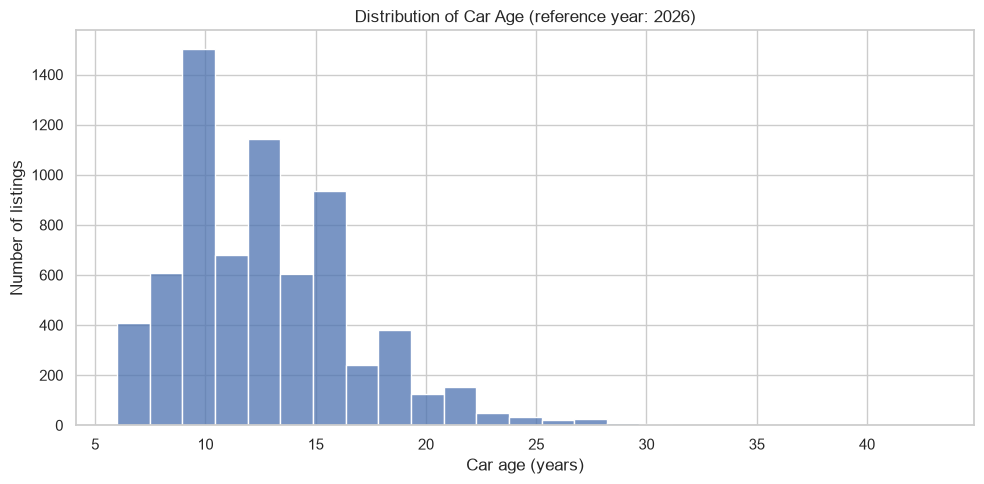

In [7]:
# 7.2 Car age distribution
plt.figure(figsize=(10, 5))
sns.histplot(df["car_age"], bins=25, kde=False)
plt.title(f"Distribution of Car Age (reference year: {REFERENCE_YEAR})")
plt.xlabel("Car age (years)")
plt.ylabel("Number of listings")
plt.tight_layout()
plt.savefig(SCREENSHOTS_DIR / "car_age_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

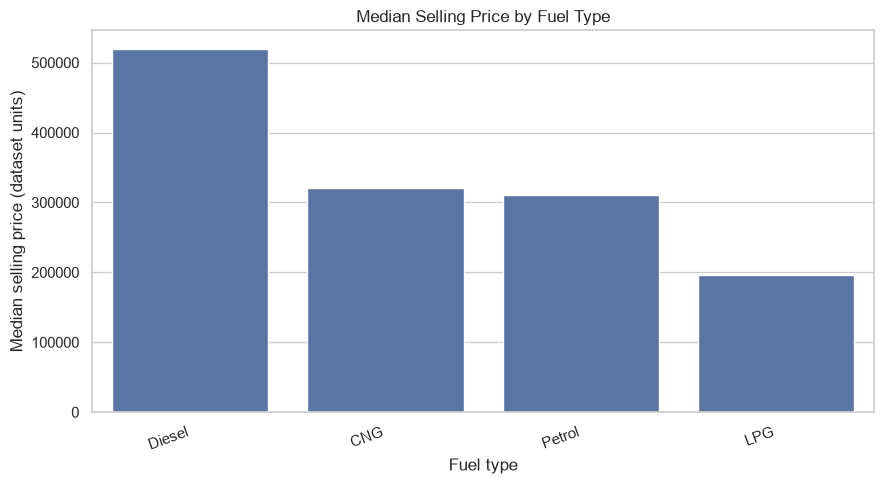

,fuel,selling_price
0,Diesel,520000.0
1,CNG,320000.0
2,Petrol,310000.0
3,LPG,195500.0


In [8]:
# 7.3 Average selling price by fuel type
fuel_price = (
    df.dropna(subset=["fuel"])
      .groupby("fuel", observed=False)["selling_price"]
      .median()
      .sort_values(ascending=False)
      .reset_index()
)

plt.figure(figsize=(9, 5))
sns.barplot(data=fuel_price, x="fuel", y="selling_price")
plt.title("Median Selling Price by Fuel Type")
plt.xlabel("Fuel type")
plt.ylabel("Median selling price (dataset units)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(SCREENSHOTS_DIR / "median_price_by_fuel.png", dpi=160, bbox_inches="tight")
plt.show()

display(fuel_price)

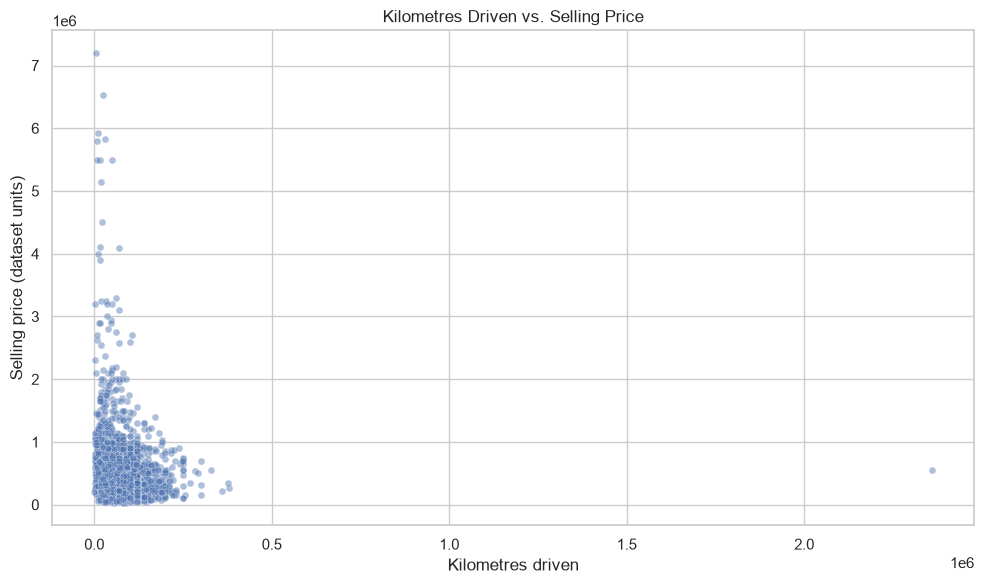

In [9]:
# 7.4 Kilometres driven versus selling price
plot_df = df.dropna(subset=["km_driven", "selling_price"]).copy()
# Use a sample for a readable chart when the dataset is large.
if len(plot_df) > 3000:
    plot_df = plot_df.sample(3000, random_state=RANDOM_STATE)

plt.figure(figsize=(10, 6))
sns.scatterplot(data=plot_df, x="km_driven", y="selling_price", alpha=0.45, s=25)
plt.title("Kilometres Driven vs. Selling Price")
plt.xlabel("Kilometres driven")
plt.ylabel("Selling price (dataset units)")
plt.tight_layout()
plt.savefig(SCREENSHOTS_DIR / "km_driven_vs_price.png", dpi=160, bbox_inches="tight")
plt.show()

### EDA interpretation guide

Use the plots and tables above to write evidence-based observations in your own words if your internship report asks for them. Common patterns to check include:

- Selling prices may be right-skewed because a small number of cars are much more expensive than the majority.
- Older cars and cars with higher kilometres driven may often sell for less, though there will be exceptions.
- Median prices can differ across fuel types, but these differences may also reflect car age, brand, power, and vehicle segment.
- A relationship visible in a chart is not proof that one feature causes a price change.

Do not write that a pattern is present unless your own generated output supports it.

## 8. Select features and split into training and test sets

We predict `selling_price`. The raw `selling_price` is never included as an input feature. We also exclude `name` and `torque`, as described above. A held-out test set is kept separate until model evaluation.

In [10]:
target = "selling_price"

candidate_features = [
    "brand", "year", "car_age", "km_driven", "fuel", "seller_type",
    "transmission", "owner", "mileage", "engine", "max_power", "seats"
]
feature_columns = [col for col in candidate_features if col in df.columns]

X = df[feature_columns].copy()
y = df[target].copy()

categorical_features = X.select_dtypes(include=["object", "string", "category"]).columns.tolist()
numeric_features = [col for col in X.columns if col not in categorical_features]

print("Features used:", feature_columns)
print("Categorical features:", categorical_features)
print("Numerical features:", numeric_features)
print(f"Target rows: {len(y):,}")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print(f"\nTraining rows: {len(X_train):,}")
print(f"Test rows: {len(X_test):,}")

Features used: ['brand', 'year', 'car_age', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage', 'engine', 'max_power', 'seats']
Categorical features: ['brand', 'fuel', 'seller_type', 'transmission', 'owner']
Numerical features: ['year', 'car_age', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']
Target rows: 6,926

Training rows: 5,540
Test rows: 1,386


## 9. Build preprocessing pipelines

A machine-learning model cannot directly learn from text categories or missing values. We therefore use a `ColumnTransformer`:

- **Numerical columns:** fill missing values with the median.
- **Categorical columns:** fill missing values with the most frequent category, then one-hot encode categories.
- **Model pipeline:** apply preprocessing and model fitting together.

This is safer than imputing or encoding the entire dataset before splitting, because each imputer learns its values from the training data only. The same transformations are then applied to the test data.

In [11]:
numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_preprocessor, numeric_features),
        ("cat", categorical_preprocessor, categorical_features)
    ],
    remainder="drop"
)

print("Preprocessing pipeline configured.")

Preprocessing pipeline configured.


## 10. Train and compare regression models

We compare four approaches:

1. **Median baseline:** predicts the training-set median for every car. This provides a simple reference point.
2. **Linear Regression:** a straightforward linear model that acts as an interpretable benchmark.
3. **Random Forest Regressor:** combines many decision trees and can learn nonlinear relationships.
4. **Extra Trees Regressor:** another tree-ensemble model that introduces additional randomness when building trees.

The same preprocessing pipeline is fitted separately for each model. Results are calculated on the held-out test set.

In [12]:
models = {
    "Median Baseline": DummyRegressor(strategy="median"),
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=160,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=160,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

fitted_models = {}
predictions = {}
results = []

for model_name, estimator in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])

    print(f"Training {model_name}...")
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    fitted_models[model_name] = pipeline
    predictions[model_name] = y_pred

    results.append({
        "Model": model_name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results).sort_values("MAE").reset_index(drop=True)
display(results_df.round(3))

Training Median Baseline...
Training Linear Regression...
Training Random Forest...
Training Extra Trees...


,Model,MAE,RMSE,R2
0,Random Forest,71784.901,121807.500,0.932
1,Extra Trees,76265.673,154081.593,0.892
2,Linear Regression,167848.793,298214.996,0.595
3,Median Baseline,259546.730,478963.265,-0.046


### How to interpret the comparison

- The median baseline is a reference, not a serious car-pricing model.
- Lower MAE means a smaller average absolute prediction error on this test split.
- Lower RMSE means fewer/lower large prediction errors, with large errors penalized more strongly.
- Higher R² generally indicates a better fit relative to predicting the mean, but a high R² alone does not guarantee that every prediction is accurate.
- Model rankings can change with a different train/test split or dataset. We use a fixed random seed so the results are reproducible.

The notebook selects the model with the lowest test MAE for the next inspection step. This is a transparent, predefined selection rule rather than a claim that one model is universally best.

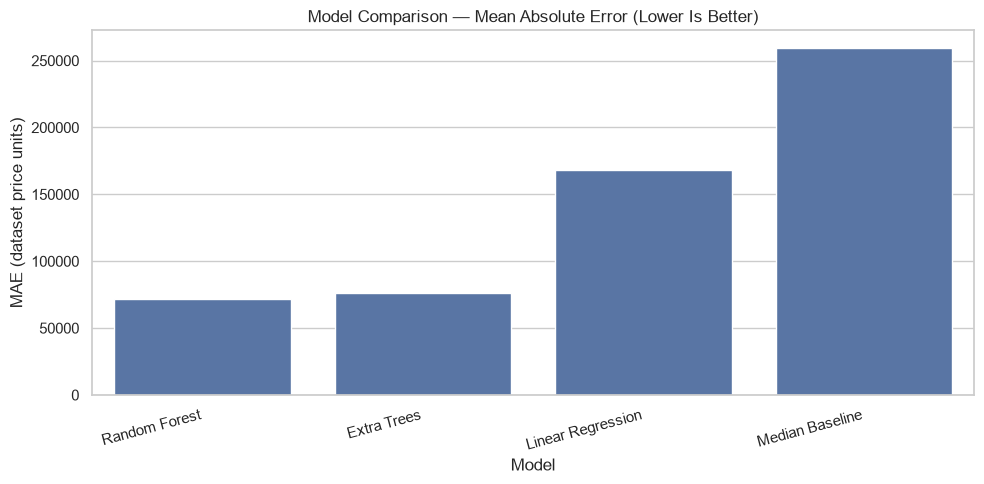

Selected model by lowest test MAE: Random Forest


In [13]:
# Plot MAE for a compact model comparison chart.
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="Model", y="MAE")
plt.title("Model Comparison — Mean Absolute Error (Lower Is Better)")
plt.xlabel("Model")
plt.ylabel("MAE (dataset price units)")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig(SCREENSHOTS_DIR / "model_comparison_mae.png", dpi=160, bbox_inches="tight")
plt.show()

best_model_name = results_df.loc[0, "Model"]
best_model = fitted_models[best_model_name]
best_predictions = predictions[best_model_name]

print("Selected model by lowest test MAE:", best_model_name)

## 11. Evaluate the selected model

We examine predicted versus actual prices and the distribution of residuals. A residual is `actual price − predicted price`. Residuals close to zero are better; patterns or very large residuals can indicate that some types of cars are harder for the model to price accurately.

In [14]:
evaluation = {
    "Selected model": best_model_name,
    "MAE": mean_absolute_error(y_test, best_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_test, best_predictions)),
    "R2": r2_score(y_test, best_predictions)
}
display(pd.DataFrame([evaluation]).round(3))

,Selected model,MAE,RMSE,R2
0,Random Forest,71784.901,121807.5,0.932


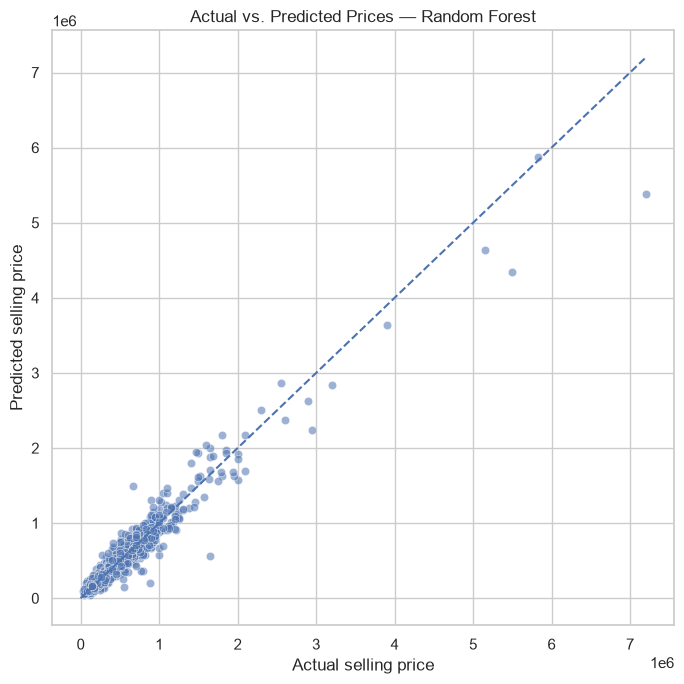

In [15]:
# Actual vs predicted plot
actual_pred_df = pd.DataFrame({
    "Actual price": y_test.to_numpy(),
    "Predicted price": best_predictions
})

plt.figure(figsize=(7, 7))
sns.scatterplot(data=actual_pred_df, x="Actual price", y="Predicted price", alpha=0.55)
max_val = max(actual_pred_df["Actual price"].max(), actual_pred_df["Predicted price"].max())
plt.plot([0, max_val], [0, max_val], linestyle="--")
plt.title(f"Actual vs. Predicted Prices — {best_model_name}")
plt.xlabel("Actual selling price")
plt.ylabel("Predicted selling price")
plt.tight_layout()
plt.savefig(SCREENSHOTS_DIR / "actual_vs_predicted.png", dpi=160, bbox_inches="tight")
plt.show()

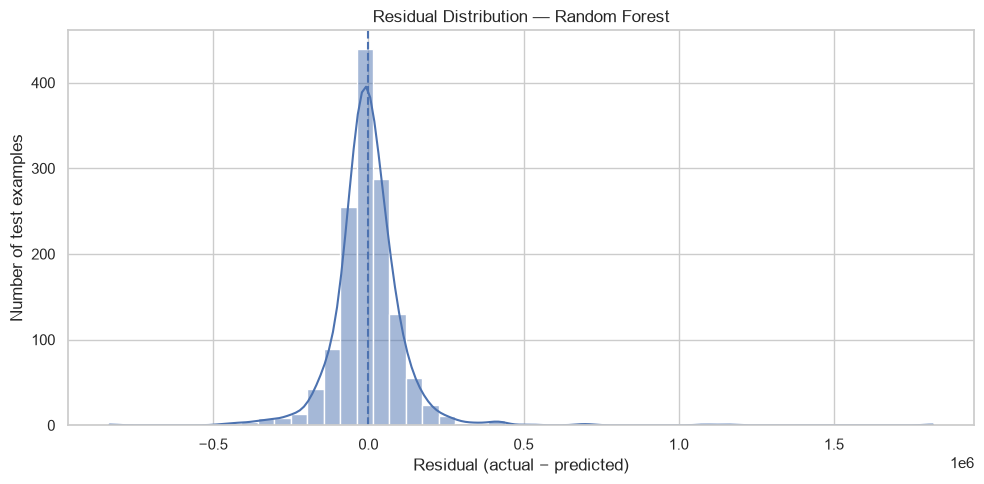

Mean residual: -612.915
Median absolute error: 47142.785


In [16]:
# Residual distribution
residuals = y_test.to_numpy() - best_predictions

plt.figure(figsize=(10, 5))
sns.histplot(residuals, bins=50, kde=True)
plt.axvline(0, linestyle="--")
plt.title(f"Residual Distribution — {best_model_name}")
plt.xlabel("Residual (actual − predicted)")
plt.ylabel("Number of test examples")
plt.tight_layout()
plt.savefig(SCREENSHOTS_DIR / "residual_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

print("Mean residual:", round(float(np.mean(residuals)), 3))
print("Median absolute error:", round(float(np.median(np.abs(residuals))), 3))

## 12. Understand which features matter

For tree-based models, feature importance can provide a rough view of which transformed inputs contributed most to the fitted ensemble. One-hot encoding expands categorical columns into separate binary columns, so the chart may show entries such as `brand_Maruti` or `fuel_Diesel`.

**Caution:** Feature importance is not proof of causation. Correlated inputs can share or distort importance, and the values do not tell us whether a feature raises or lowers price. We show this plot only when the selected model supports the standard tree `feature_importances_` attribute.

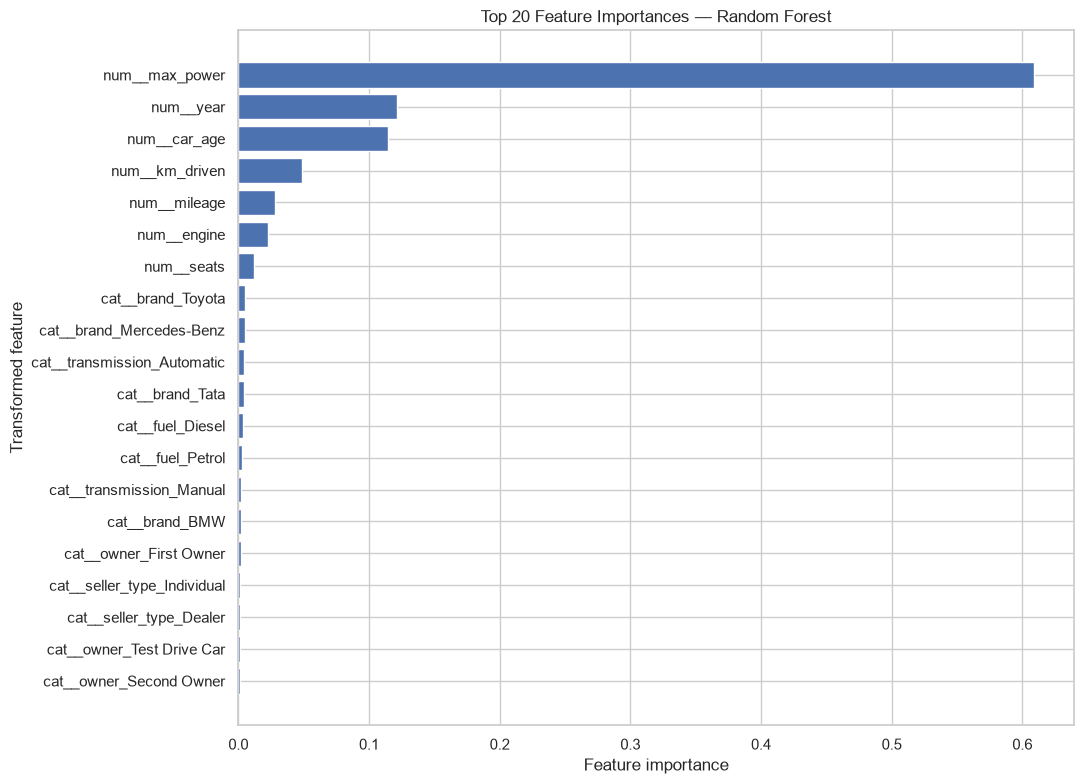

,Feature,Importance
0,num__max_power,0.609065
1,num__year,0.121346
2,num__car_age,0.114241
3,num__km_driven,0.049012
4,num__mileage,0.028110
5,num__engine,0.023040
6,num__seats,0.012220
7,cat__brand_Toyota,0.005145
8,cat__brand_Mercedes-Benz,0.005036
9,cat__transmission_Automatic,0.004241


In [17]:
selected_estimator = best_model.named_steps["model"]

if hasattr(selected_estimator, "feature_importances_"):
    transformed_names = best_model.named_steps["preprocessor"].get_feature_names_out()
    importances = selected_estimator.feature_importances_

    importance_df = (
        pd.DataFrame({"Feature": transformed_names, "Importance": importances})
          .sort_values("Importance", ascending=False)
          .head(20)
          .sort_values("Importance", ascending=True)
    )

    plt.figure(figsize=(11, 8))
    plt.barh(importance_df["Feature"], importance_df["Importance"])
    plt.title(f"Top 20 Feature Importances — {best_model_name}")
    plt.xlabel("Feature importance")
    plt.ylabel("Transformed feature")
    plt.tight_layout()
    plt.savefig(SCREENSHOTS_DIR / "feature_importance.png", dpi=160, bbox_inches="tight")
    plt.show()

    display(importance_df.sort_values("Importance", ascending=False).head(20).reset_index(drop=True))
else:
    print(
        f"{best_model_name} does not expose tree-based feature_importances_. "
        "No feature-importance chart was generated for this selected estimator."
    )

## 13. Inspect sample predictions

The following table places actual and predicted prices side by side, with the absolute error. It is useful for a quick sanity check and for explaining that the model makes estimates rather than exact guarantees.

In [18]:
sample_predictions = X_test.copy()
sample_predictions["Actual selling price"] = y_test
sample_predictions["Predicted selling price"] = best_predictions
sample_predictions["Absolute error"] = np.abs(
    sample_predictions["Actual selling price"] - sample_predictions["Predicted selling price"]
)

display(sample_predictions.sort_values("Absolute error").head(10).round(2))

,brand,year,car_age,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats,Actual selling price,Predicted selling price,Absolute error
1323,Maruti,2014,12,50000,Petrol,Individual,Manual,First Owner,22.74,796,47.3,5.0,235000,235018.08,18.08
5161,Maruti,2014,12,60000,Diesel,Individual,Manual,First Owner,23.4,1248,74.0,5.0,500000,500077.65,77.65
3455,Maruti,2016,10,70000,Diesel,Individual,Manual,Second Owner,25.2,1248,74.0,5.0,565000,564903.68,96.32
3394,Mahindra,2014,12,70000,Diesel,Individual,Manual,First Owner,15.96,2523,62.1,7.0,550000,549744.08,255.92
7402,Hyundai,2012,14,83000,Petrol,Individual,Automatic,First Owner,15.74,1591,121.3,5.0,475000,475281.91,281.91
44,Maruti,2018,8,23300,Petrol,Dealer,Automatic,First Owner,18.5,1197,83.14,5.0,675000,674500.20,499.8
7422,Hyundai,2003,23,120000,Petrol,Individual,Manual,Third Owner,<NA>,<NA>,<NA>,<NA>,70000,69475.59,524.41
5168,Ford,2018,8,15000,Petrol,Individual,Manual,First Owner,18.16,1196,86.8,5.0,590000,589465.94,534.06
3039,Mahindra,2017,9,70000,Diesel,Individual,Manual,First Owner,15.96,2523,62.1,7.0,710000,710696.06,696.06
458,Nissan,2015,11,90000,Diesel,Individual,Manual,First Owner,20.45,1461,83.8,5.0,580000,580723.28,723.28


## 14. Try a prediction for an existing test example

To avoid inventing a fictional vehicle specification, this cell uses the first row of the held-out test set as a demonstration. The trained pipeline automatically applies the same imputing and encoding steps as during training.

In [19]:
example_car = X_test.iloc[[0]]
example_actual = float(y_test.iloc[0])
example_predicted = float(best_model.predict(example_car)[0])

display(example_car)
print(f"Actual selling price:    {example_actual:,.2f}")
print(f"Predicted selling price: {example_predicted:,.2f}")
print(f"Absolute error:          {abs(example_actual - example_predicted):,.2f}")

,brand,year,car_age,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats
8077,Toyota,2009,17,250000,Diesel,Individual,Manual,First Owner,12.8,2494,102.0,7.0


Actual selling price:    550,000.00
Predicted selling price: 687,270.96
Absolute error:          137,270.96


## 15. Save a model-results table and verify screenshots

This cell saves the model comparison metrics to a CSV file in the project folder and lists the PNG charts generated by the notebook. 

In [20]:
metrics_path = PROJECT_DIR / "model_metrics.csv"
results_df.to_csv(metrics_path, index=False)

print("Saved model metrics to:", metrics_path)
print("\nGenerated screenshot files:")
for image_path in sorted(SCREENSHOTS_DIR.glob("*.png")):
    print(f"- {image_path.name} ({image_path.stat().st_size:,} bytes)")

Saved model metrics to: C:\Users\user\OIBSIP\OIBSIP\DataScience-Task3-CarPricePrediction\model_metrics.csv

Generated screenshot files:
- actual_vs_predicted.png (88,290 bytes)
- car_age_distribution.png (40,743 bytes)
- feature_importance.png (99,783 bytes)
- km_driven_vs_price.png (96,406 bytes)
- median_price_by_fuel.png (38,762 bytes)
- model_comparison_mae.png (49,263 bytes)
- residual_distribution.png (53,881 bytes)
- selling_price_distribution.png (56,049 bytes)


## 16. Final findings and limitations

The cells below summarize the selected model's measured test performance. 

In [21]:
print("FINAL PROJECT SUMMARY")
print("=" * 60)
print(f"Cleaned dataset rows: {len(df):,}")
print(f"Input features: {len(feature_columns)}")
print(f"Training examples: {len(X_train):,}")
print(f"Test examples: {len(X_test):,}")
print(f"Selected model (lowest test MAE): {best_model_name}")
print(f"MAE:  {mean_absolute_error(y_test, best_predictions):,.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, best_predictions)):,.2f}")
print(f"R²:   {r2_score(y_test, best_predictions):.4f}")
print(f"Charts saved: {len(list(SCREENSHOTS_DIR.glob('*.png')))}")

FINAL PROJECT SUMMARY
Cleaned dataset rows: 6,926
Input features: 12
Training examples: 5,540
Test examples: 1,386
Selected model (lowest test MAE): Random Forest
MAE:  71,784.90
RMSE: 121,807.50
R²:   0.9324
Charts saved: 8


### Limitations to mention in a report

1. **Source and market scope:** the dataset reflects a particular collection of used-car listings and may not represent current prices or every market.
2. **No time-based validation:** the evaluation uses a random train/test split, not a split by listing date. It estimates performance on similar held-out records, not necessarily future-market performance.
3. **Outliers and data quality:** unusually high prices, incomplete specifications, and listing inconsistencies can affect training and metrics.
4. **Feature coverage:** brand is extracted from the first token in the name; some names may be inconsistently formatted. The complex torque field is excluded.
5. **Model interpretability:** tree feature importance is descriptive and does not imply causation.
6. **Not a guaranteed quote:** predictions should be treated as estimates, not as an official valuation or purchase recommendation.

### Conclusion

This project demonstrates an end-to-end regression workflow: data inspection, cleaning, feature engineering, exploratory analysis, train/test separation, reusable preprocessing pipelines, model comparison, evaluation, and feature-importance analysis. The best-performing model in this run is selected using the lowest MAE on the held-out test set. 